# Telco Customer Churn — Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


## 1. Load Data & Inspect Shape

In [2]:
data_path = Path('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = pd.read_csv(data_path)
df.shape


(7043, 21)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. TotalCharges Whitespace Anomaly & Resolution

In [5]:
missing_spaces = (df['TotalCharges'].str.strip() == '').sum()
print('Missing whitespace count in TotalCharges:', missing_spaces)
df[df['TotalCharges'].str.strip() == ''][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]


Missing whitespace count in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0.0
df['TotalCharges'].isna().sum()


np.int64(0)

## 3. Class Imbalance Analysis

In [7]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100
pd.DataFrame({'Count': churn_counts, 'Percentage': churn_pct})


,Count,Percentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


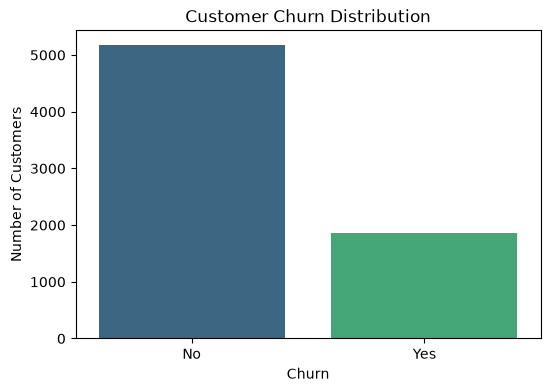

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='viridis', legend=False, ax=ax)
ax.set_title('Customer Churn Distribution')
ax.set_ylabel('Number of Customers')
Path('../reports/figures').mkdir(parents=True, exist_ok=True)
plt.savefig('../reports/figures/churn_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. Feature Relationships with Churn

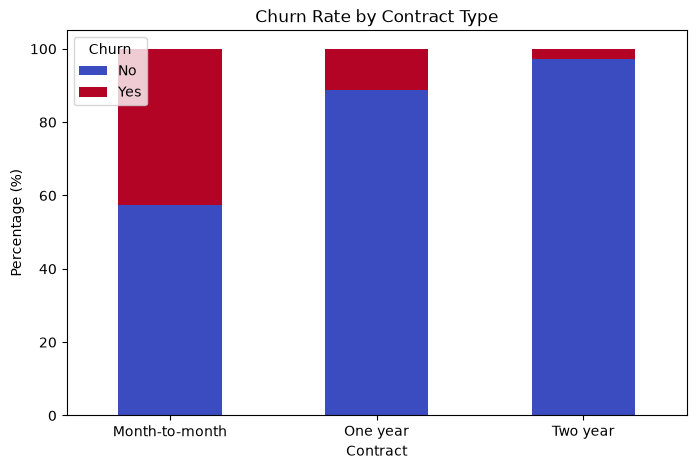

In [9]:
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100
fig, ax = plt.subplots(figsize=(8, 5))
contract_churn.plot(kind='bar', stacked=True, ax=ax, colormap='coolwarm')
ax.set_title('Churn Rate by Contract Type')
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('Contract')
plt.xticks(rotation=0)
plt.savefig('../reports/figures/contract_churn.png', dpi=300, bbox_inches='tight')
plt.show()


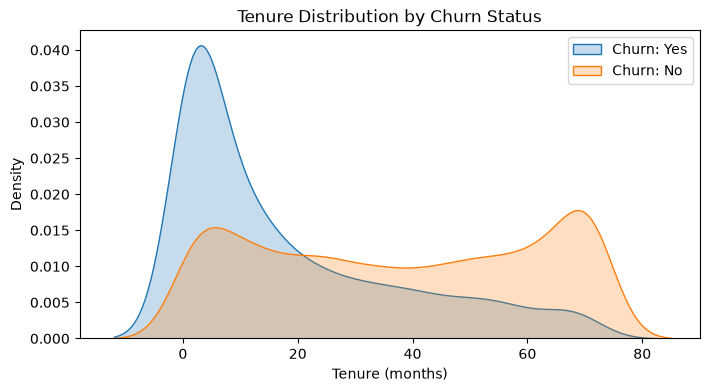

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=df[df['Churn'] == 'Yes']['tenure'], label='Churn: Yes', fill=True, ax=ax)
sns.kdeplot(data=df[df['Churn'] == 'No']['tenure'], label='Churn: No', fill=True, ax=ax)
ax.set_title('Tenure Distribution by Churn Status')
ax.set_xlabel('Tenure (months)')
ax.legend()
plt.savefig('../reports/figures/tenure_churn_kde.png', dpi=300, bbox_inches='tight')
plt.show()


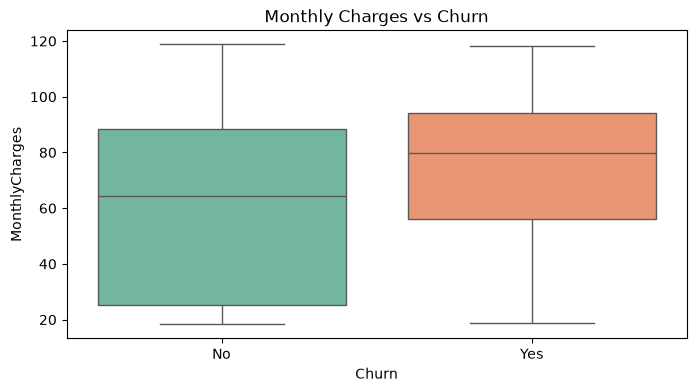

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=ax)
ax.set_title('Monthly Charges vs Churn')
plt.savefig('../reports/figures/monthly_charges_churn.png', dpi=300, bbox_inches='tight')
plt.show()
